In [1]:
import os
import pandas as pd
import numpy as np
from google.colab import files
from sklearn.model_selection import train_test_split

# 1. Subir tus 7 archivos CSV locales (si aún no están subidos)
print("Por favor, selecciona y sube tus 7 archivos CSV locales:")
uploaded = files.upload()

# Mapas de conversión bidireccionales para evitar nulos
mapa_texto_a_num = {
    'No Tóxico': 0, 'no_toxico': 0, 0: 0, 0.0: 0,
    'Lenguaje Ofensivo': 1, 'lenguaje_ofensivo': 1, 1: 1, 1.0: 1,
    'Discurso de Odio': 2, 'discurso_de_odio': 2, 2: 2, 2.0: 2,
    'Amenazas/Violencia': 3, 'amenazas_violencia': 3, 3: 3, 3.0: 3
}

# 2. Leer y procesar los CSVs locales
dfs_locales = []
for file_name in uploaded.keys():
    if file_name.endswith('.csv'):
        df_temp = pd.read_csv(file_name)

        # Homogeneizar la columna label si viene con nombre 'clase'
        if 'label' not in df_temp.columns and 'clase' in df_temp.columns:
            df_temp['label'] = df_temp['clase'].map(mapa_texto_a_num)
        elif 'label' in df_temp.columns:
            df_temp['label'] = df_temp['label'].map(mapa_texto_a_num)

        dfs_locales.append(df_temp)
        print(f"✓ Cargado local: {file_name} ({len(df_temp)} filas)")

df_local_unificado = pd.concat(dfs_locales, ignore_index=True)

# 3. Descargar y formatear el dataset externo de Davidson et al.
print("\nDescargando dataset externo de Davidson et al. desde GitHub...")
url_davidson = "https://raw.githubusercontent.com/t-davidson/hate-speech-and-offensive-language/master/data/labeled_data.csv"
df_davidson = pd.read_csv(url_davidson)

# Davidson: 0=Hate Speech (2), 1=Offensive (1), 2=Neither (0)
mapa_davidson = {0: 2, 1: 1, 2: 0}

df_davidson_mapped = pd.DataFrame({
    'texto_original': df_davidson['tweet'],
    'texto_modelo': df_davidson['tweet'],
    'label': df_davidson['class'].map(mapa_davidson),
    'origen': 'davidson_dataset_externo'
})

# 4. Concatenar y LIMPIAR valores NaN
df_final = pd.concat([df_local_unificado, df_davidson_mapped], ignore_index=True)

# Eliminar nulos en la columna de texto y etiqueta
filas_antes = len(df_final)
df_final = df_final.dropna(subset=['texto_modelo', 'label']).copy()
df_final['label'] = df_final['label'].astype(int)

# Regenerar columna textual 'clase'
nombres_clases = {0: 'No Tóxico', 1: 'Lenguaje Ofensivo', 2: 'Discurso de Odio', 3: 'Amenazas/Violencia'}
df_final['clase'] = df_final['label'].map(nombres_clases)

print(f"\n✓ Registros limpios sin NaN: {len(df_final)} (se descartaron {filas_antes - len(df_final)} filas inconsistentes)")
print("\n=== DISTRIBUCIÓN FINAL DE CLASES ===")
print(df_final['clase'].value_counts())

# 5. Partición estratificada 70% Train / 15% Val / 15% Test
train_df, test_val_df = train_test_split(df_final, test_size=0.30, random_state=42, stratify=df_final['label'])
val_df, test_df = train_test_split(test_val_df, test_size=0.50, random_state=42, stratify=test_val_df['label'])

# Guardar archivos procesados
train_df.to_csv('train_unificado.csv', index=False)
val_df.to_csv('val_unificado.csv', index=False)
test_df.to_csv('test_unificado.csv', index=False)

print(f"\n✓ Archivos procesados con éxito:")
print(f" - train_unificado.csv: {len(train_df)} filas")
print(f" - val_unificado.csv:   {len(val_df)} filas")
print(f" - test_unificado.csv:  {len(test_df)} filas")

Por favor, selecciona y sube tus 7 archivos CSV locales:


Saving test.csv to test.csv
Saving test_adversarial.csv to test_adversarial.csv
Saving train.csv to train.csv
Saving val.csv to val.csv
✓ Cargado local: test.csv (460 filas)
✓ Cargado local: test_adversarial.csv (144 filas)
✓ Cargado local: train.csv (12641 filas)
✓ Cargado local: val.csv (459 filas)

Descargando dataset externo de Davidson et al. desde GitHub...

✓ Registros limpios sin NaN: 38343 (se descartaron 144 filas inconsistentes)

=== DISTRIBUCIÓN FINAL DE CLASES ===
clase
Lenguaje Ofensivo     22732
No Tóxico              9556
Discurso de Odio       4168
Amenazas/Violencia     1887
Name: count, dtype: int64

✓ Archivos procesados con éxito:
 - train_unificado.csv: 26840 filas
 - val_unificado.csv:   5751 filas
 - test_unificado.csv:  5752 filas


In [2]:
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
from transformers import (
    XLMRobertaTokenizer,
    XLMRobertaForSequenceClassification,
    Trainer,
    TrainingArguments,
    EarlyStoppingCallback
)
from datasets import Dataset
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score
from sklearn.utils.class_weight import compute_class_weight

# 1. Función para encontrar dinámicamente la columna de texto
def obtener_columna_texto(df):
    candidatos = ['texto_modelo', 'texto_original', 'tweet', 'text', 'texto', 'comment', 'contenido']
    for col in candidatos:
        if col in df.columns:
            return col
    # Si ninguna coincide, tomar la primera columna de tipo objeto/string
    for col in df.columns:
        if df[col].dtype == 'object' and col not in ['clase', 'origen']:
            return col
    raise ValueError("No se encontró ninguna columna de texto válida en el DataFrame.")

# 2. Cargar conjuntos unificados
train_df = pd.read_csv('train_unificado.csv')
val_df = pd.read_csv('val_unificado.csv')

col_train = obtener_columna_texto(train_df)
col_val = obtener_columna_texto(val_df)

print(f"✓ Columna detectada en Train: '{col_train}'")
print(f"✓ Columna detectada en Val:   '{col_val}'")

# Asignar a 'text_input' asegurando formato string
train_df['text_input'] = train_df[col_train].astype(str)
val_df['text_input'] = val_df[col_val].astype(str)
train_df['label'] = train_df['label'].astype(int)
val_df['label'] = val_df['label'].astype(int)

# 3. Tokenización con XLM-RoBERTa
MODEL_NAME = "xlm-roberta-base"
tokenizer = XLMRobertaTokenizer.from_pretrained(MODEL_NAME)

def tokenize_function(examples):
    return tokenizer(examples['text_input'], padding="max_length", truncation=True, max_length=128)

train_ds = Dataset.from_pandas(train_df[['text_input', 'label']]).map(tokenize_function, batched=True)
val_ds = Dataset.from_pandas(val_df[['text_input', 'label']]).map(tokenize_function, batched=True)

# 4. Cálculo de Pesos Balanceados para Cross-Entropy Loss
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1, 2, 3]),
    y=train_df['label'].values
)
weights_tensor = torch.tensor(class_weights, dtype=torch.float).to("cuda" if torch.cuda.is_available() else "cpu")

print("\nPesos asignados por clase [0: No Tóxico, 1: Ofensivo, 2: Odio, 3: Amenaza]:")
print(weights_tensor)

# 5. Custom Trainer con Pérdida Ponderada
class CustomWeightedTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs.get("labels")
        outputs = model(**inputs)
        logits = outputs.get("logits")
        loss_fct = nn.CrossEntropyLoss(weight=weights_tensor)
        loss = loss_fct(logits.view(-1, self.model.config.num_labels), labels.view(-1))
        return (loss, outputs) if return_outputs else loss

# 6. Métrica de Evaluación Completa
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    acc = accuracy_score(labels, preds)
    f1_macro = f1_score(labels, preds, average="macro")
    recall = recall_score(labels, preds, average=None, zero_division=0)
    precision = precision_score(labels, preds, average=None, zero_division=0)

    return {
        "accuracy": acc,
        "f1_macro": f1_macro,
        "rec_no_toxico": recall[0],
        "rec_ofensivo": recall[1],
        "rec_odio": recall[2],
        "rec_amenaza": recall[3],
        "prec_no_toxico": precision[0],
        "prec_ofensivo": precision[1],
        "prec_odio": precision[2],
        "prec_amenaza": precision[3]
    }

# 7. Configuración de Hiperparámetros y Fine-Tuning
model = XLMRobertaForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=4)

training_args = TrainingArguments(
    output_dir="./results_xlm_roberta_unificado",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    greater_is_better=True,
    logging_steps=100,
    seed=42
)

trainer = CustomWeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)]
)

# Iniciar entrenamiento
trainer.train()

✓ Columna detectada en Train: 'texto_modelo'
✓ Columna detectada en Val:   'texto_modelo'


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Map:   0%|          | 0/26840 [00:00<?, ? examples/s]

Map:   0%|          | 0/5751 [00:00<?, ? examples/s]

... (7 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=5034, training_loss=0.5342844897525197, metrics={'train_runtime': 2423.0262, 'train_samples_per_second': 33.231, 'train_steps_per_second': 2.078, 'total_flos': 5296520653332480.0, 'train_loss': 0.5342844897525197, 'epoch': 3.0})

In [3]:
import pandas as pd
import numpy as np
import torch

# 1. Cargar el archivo adversarial
df_adv = pd.read_csv('test_adversarial.csv')

# 2. Identificar dinámicamente la columna de texto y la columna de grupo
col_texto = obtener_columna_texto(df_adv)

col_grupo = None
candidatos_grupo = ['grupo', 'Grupo', 'grupo_de_prueba', 'grupo_prueba', 'categoria', 'subclase', 'base']
for col in candidatos_grupo:
    if col in df_adv.columns:
        col_grupo = col
        break

if col_grupo is None:
    for col in df_adv.columns:
        # Uso de raw string (r'...') para evitar el SyntaxWarning de la expresión regular
        if df_adv[col].astype(str).str.contains(r'Jerga|D\.', case=False, regex=True).any():
            col_grupo = col
            break

print(f"✓ Columna de texto detectada: '{col_texto}'")
print(f"✓ Columna de grupo detectada: '{col_grupo}'")

# 3. Función de inferencia con XLM-RoBERTa
def predecir_texto(texto):
    inputs = tokenizer(str(texto), return_tensors="pt", truncation=True, max_length=128, padding=True).to(model.device)
    with torch.no_grad():
        outputs = model(**inputs)
        probs = torch.softmax(outputs.logits, dim=1).cpu().numpy()[0]
        pred_label = np.argmax(probs)
    return pred_label

# 4. Generar predicciones
df_adv['pred_label'] = df_adv[col_texto].apply(predecir_texto)

# Mapeo de labels a texto
nombres_clases = {0: 'No Tóxico', 1: 'Lenguaje Ofensivo', 2: 'Discurso de Odio', 3: 'Amenazas/Violencia'}
df_adv['pred_clase'] = df_adv['pred_label'].map(nombres_clases)

# 5. Filtrar el Grupo D (Jerga Inofensiva) y calcular Tasa de Falsos Positivos
if col_grupo:
    grupo_d = df_adv[df_adv[col_grupo].astype(str).str.contains(r'Jerga|D\.', case=False, regex=True)]
    fp_jerga = (grupo_d['pred_label'] != 0).sum()
    total_jerga = len(grupo_d)

    print("\n" + "="*50)
    print("  EVALUACIÓN ADVERSARIAL EN JERGA SALVADOREÑA")
    print("="*50)
    print(f"Total casos probados: {total_jerga}")
    print(f"Falsos Positivos: {fp_jerga}")
    print(f"Tasa de Falsos Positivos (FPR): {fp_jerga / total_jerga * 100:.2f}%")
    print("="*50)

    if fp_jerga > 0:
        print("\nDetalle de falsos positivos detectados:")
        print(grupo_d[grupo_d['pred_label'] != 0][[col_texto, 'pred_clase']])

✓ Columna de texto detectada: 'texto'
✓ Columna de grupo detectada: 'grupo_de_prueba'

  EVALUACIÓN ADVERSARIAL EN JERGA SALVADOREÑA
Total casos probados: 26
Falsos Positivos: 0
Tasa de Falsos Positivos (FPR): 0.00%


✓ Evaluando sobre 'test_unificado.csv' (5752 filas)...

             REPORTE DE METRICAS DE CLASIFICACIÓN
                    precision    recall  f1-score   support

         No Tóxico     0.8262    0.8982    0.8607      1434
 Lenguaje Ofensivo     0.9459    0.8821    0.9129      3410
  Discurso de Odio     0.6171    0.7376    0.6720       625
Amenazas/Violencia     0.7782    0.7314    0.7541       283

          accuracy                         0.8630      5752
         macro avg     0.7919    0.8123    0.7999      5752
      weighted avg     0.8721    0.8630    0.8659      5752

Accuracy Global: 86.30%
F1-Score Macro:  0.7999

=== TASA DE FALSOS POSITIVOS (FPR) POR CLASE ===
 - No Tóxico           : FPR = 6.28% (271 falsos positivos)
 - Lenguaje Ofensivo   : FPR = 7.34% (172 falsos positivos)
 - Discurso de Odio    : FPR = 5.58% (286 falsos positivos)
 - Amenazas/Violencia  : FPR = 1.08% (59 falsos positivos)


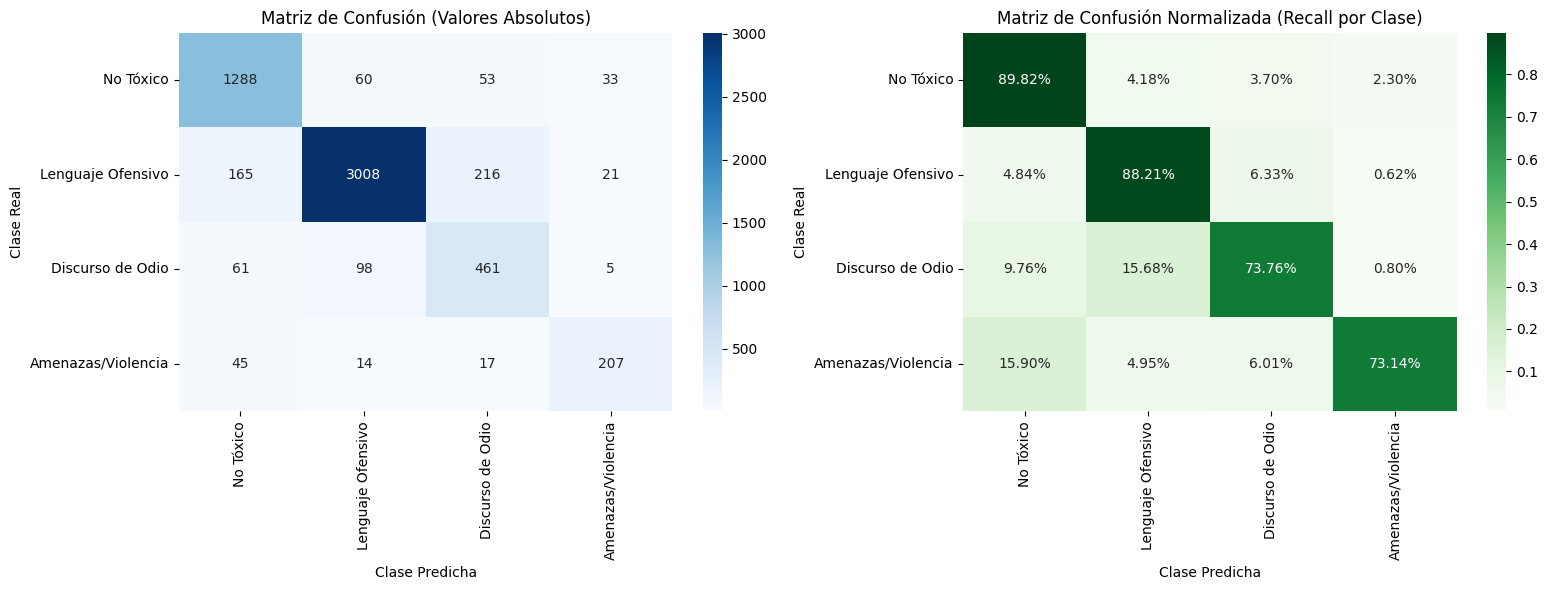

In [4]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

# 1. Cargar el conjunto de test unificado
test_df = pd.read_csv('test_unificado.csv')
col_test = obtener_columna_texto(test_df)

print(f"✓ Evaluando sobre 'test_unificado.csv' ({len(test_df)} filas)...")

# 2. Inferencia por lotes (Batch Inference) para mayor velocidad en GPU
def predecir_lote(textos, batch_size=64):
    preds = []
    probs_list = []
    model.eval()

    for i in range(0, len(textos), batch_size):
        batch = textos[i:i+batch_size]
        inputs = tokenizer(batch, return_tensors="pt", truncation=True, max_length=128, padding=True).to(model.device)
        with torch.no_grad():
            outputs = model(**inputs)
            probs = torch.softmax(outputs.logits, dim=1).cpu().numpy()
            preds.extend(np.argmax(probs, axis=1))
            probs_list.extend(probs)

    return np.array(preds), np.array(probs_list)

textos_test = test_df[col_test].astype(str).tolist()
y_true = test_df['label'].astype(int).values
y_pred, y_probs = predecir_lote(textos_test)

# 3. Reporte de Clasificación Detallado
etiquetas_nombres = ['No Tóxico', 'Lenguaje Ofensivo', 'Discurso de Odio', 'Amenazas/Violencia']
report_dict = classification_report(y_true, y_pred, target_names=etiquetas_nombres, digits=4, output_dict=True)

print("\n" + "="*65)
print("             REPORTE DE METRICAS DE CLASIFICACIÓN")
print("="*65)
print(classification_report(y_true, y_pred, target_names=etiquetas_nombres, digits=4))

f1_macro = f1_score(y_true, y_pred, average='macro')
acc = accuracy_score(y_true, y_pred)
print(f"Accuracy Global: {acc*100:.2f}%")
print(f"F1-Score Macro:  {f1_macro:.4f}")
print("="*65)

# 4. Cálculo de Matriz de Confusión y Tasas de Falsos Positivos (FPR) por clase
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

print("\n=== TASA DE FALSOS POSITIVOS (FPR) POR CLASE ===")
for i, nombre in enumerate(etiquetas_nombres):
    fp = cm[:, i].sum() - cm[i, i]
    tn = cm.sum() - (cm[i, :].sum() + cm[:, i].sum() - cm[i, i])
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    print(f" - {nombre:<20}: FPR = {fpr*100:.2f}% ({fp} falsos positivos)")

# 5. Visualización de la Matriz de Confusión
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Matriz Absoluta
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=etiquetas_nombres, yticklabels=etiquetas_nombres, ax=axes[0])
axes[0].set_title('Matriz de Confusión (Valores Absolutos)')
axes[0].set_xlabel('Clase Predicha')
axes[0].set_ylabel('Clase Real')

# Matriz Normalizada
sns.heatmap(cm_norm, annot=True, fmt='.2%', cmap='Greens', xticklabels=etiquetas_nombres, yticklabels=etiquetas_nombres, ax=axes[1])
axes[1].set_title('Matriz de Confusión Normalizada (Recall por Clase)')
axes[1].set_xlabel('Clase Predicha')
axes[1].set_ylabel('Clase Real')

plt.tight_layout()
plt.show()